# T04 - Variable de control

---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Tarea**

---

## Parametros iniciales

Se definen los parametros del activo subyacente y de la opcion asiatica que se valuara.

In [101]:
import numpy as np
from scipy.stats import norm

s0 = 100
r = 0.05
sigma = 0.2
k=100
T=1

## Precio teorico de la opcion asiatica geometrica

Se calcula el valor cerrado de la opcion asiatica geometrica, que se utilizara como variable de control.

In [102]:
volatilidad_ajustada = sigma/np.sqrt(3)
b = 0.5*(r - 0.5*volatilidad_ajustada**2)

def bs_asiatic_geom(S0, K, r, sigma, T, b_a, call_opt=True):
    d1 = (np.log(S0 / K) + (b_a + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    put = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * np.exp((b_a - r)*T) * norm.cdf(-d1)
    call = S0 * np.exp((b_a - r) * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    if call_opt:
        return call
    else:
        return put

expected_call_price = bs_asiatic_geom(s0, k, r, volatilidad_ajustada, T, b, call_opt=True)
expected_call_price

np.float64(5.546818633789201)

## Estimacion Monte Carlo con variable de control

Se simulan trayectorias del activo y se emplea el pago geometrico para reducir la varianza del estimador aritmetico.

## Generacion y visualizacion de trayectorias

Se generan trayectorias de precios bajo el movimiento geometrico browniano y se muestra una grafica de las simulaciones.

## Calculo de promedios y pagos

A partir de cada trayectoria se obtienen los promedios aritmetico y geometrico, asi como los pagos de las opciones call.

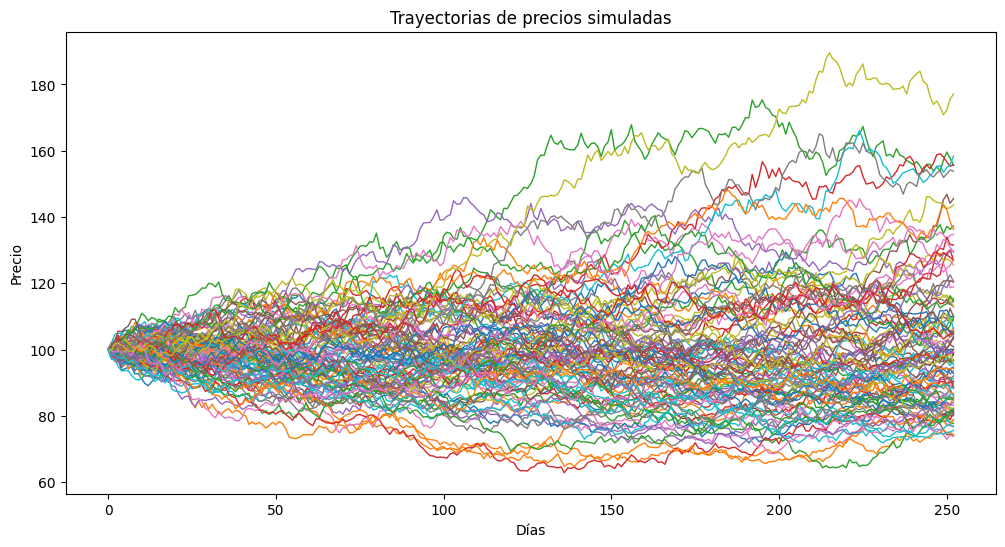

In [103]:
from scipy.stats import gmean
import matplotlib.pyplot as plt

def create_paths(S0, r, sigma, T, steps, n_paths):
    dt = T / steps
    paths = np.zeros((steps + 1, n_paths))
    paths[0, :] = S0
    for t in range(steps):
        paths[t+1, :] = paths[t, :] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * np.random.normal(0, 1, n_paths))
    return paths

trayectorias = create_paths(S0=s0, r=r, sigma=sigma, T=T, steps=252, n_paths=100)


plt.figure(figsize=(12,6))
for i in range(trayectorias.shape[1]):
    plt.plot(range(trayectorias.shape[0]), trayectorias[:, i], lw=1)
plt.title('Trayectorias de precios simuladas')
plt.xlabel('Días')
plt.ylabel('Precio')
plt.show()

In [104]:
media_arit = np.mean(trayectorias, axis=0)
media_geom = gmean(trayectorias, axis=0)

call_arit =np.maximum(media_arit - k, 0)
call_geom =np.maximum(media_geom - k, 0)

## Estimacion del coeficiente de control

Se estima el coeficiente beta que minimiza la varianza del estimador con variable de control.

In [105]:
b_est = np.sum((call_geom - np.mean(call_geom))*(call_arit - np.mean(call_arit))) / np.sum((call_geom - np.mean(call_geom))**2)
b_est

np.float64(1.0476300924529276)

## Estimacion del precio de la opcion asiatica aritmetica

Se construye el estimador ajustado por la variable de control y se calcula su media muestral.

In [106]:
yi_b = call_arit - b_est * (call_geom - expected_call_price)
np.mean(yi_b)

np.float64(5.785696244655651)

## Conclusion

La variable de control geometrica permite reducir la variabilidad de la estimacion Monte Carlo para la opcion asiatica aritmetica. Esto nos sirve dandole una guía a la simulación usando la metafora del 'palo guía'.